# Assignment 2 — RGB (Colour) to Grayscale Image

> **Question:** Write a program to convert an RGB (colour) image to a grayscale image.

**Method:**
- Case 1: $\; Gray = \dfrac{R + G + B}{3}$
- Case 2: $\; Gray = w_R R + w_G G + w_B B, \quad w_R + w_G + w_B = 1$

### Requirements
Run this cell once to install the libraries used in this notebook.

In [ ]:
%pip install numpy matplotlib opencv-python scikit-image

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

plt.rcParams['figure.dpi'] = 100


def ask(prompt, default, cast=float):
    """Read a value from the user.
    If the user just presses Enter, types something invalid, or the notebook is
    run non-interactively (no keyboard input possible), the default is used."""
    try:
        text = input(f"{prompt} [default = {default}]: ").strip()
        return cast(text) if text else default
    except Exception:
        print(f"{prompt}: no valid input, using default = {default}")
        return default


def show(images, titles, cols=None, size=4):
    """Display a list of images side by side (grayscale shown on a fixed 0-255 scale)."""
    n = len(images)
    cols = cols or n
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis('off')
    for ax, im, t in zip(axes, images, titles):
        if im.ndim == 2:
            ax.imshow(im, cmap='gray', vmin=0, vmax=1 if im.max() <= 1 else 255)
        else:
            ax.imshow(im)
        ax.set_title(t)
    plt.tight_layout()
    plt.show()

In [2]:
# Input image: set IMAGE_PATH to use your own image, otherwise a standard test image is used.
IMAGE_PATH = None   # e.g. "my_image.jpg"

if IMAGE_PATH:
    rgb = cv2.cvtColor(cv2.imread(IMAGE_PATH, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
else:
    rgb = data.astronaut()   # 'astronaut' test image from scikit-image

print("Image size:", rgb.shape, "| dtype:", rgb.dtype)

Image size: (512, 512, 3) | dtype: uint8


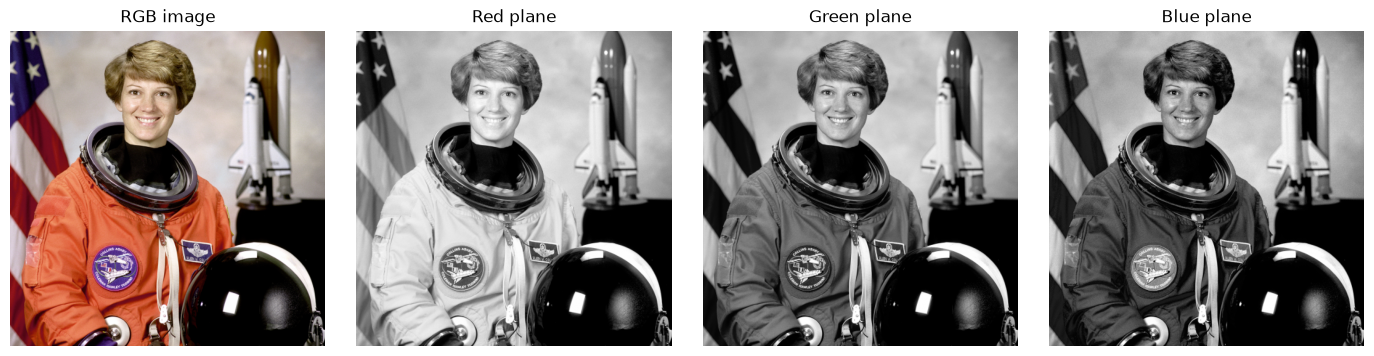

In [3]:
R, G, B = rgb[:, :, 0], rgb[:, :, 1], rgb[:, :, 2]
show([rgb, R, G, B], ['RGB image', 'Red plane', 'Green plane', 'Blue plane'], size=3.5)

## Case 1

> **Case 1:** By taking the mean (average) of the three planes.

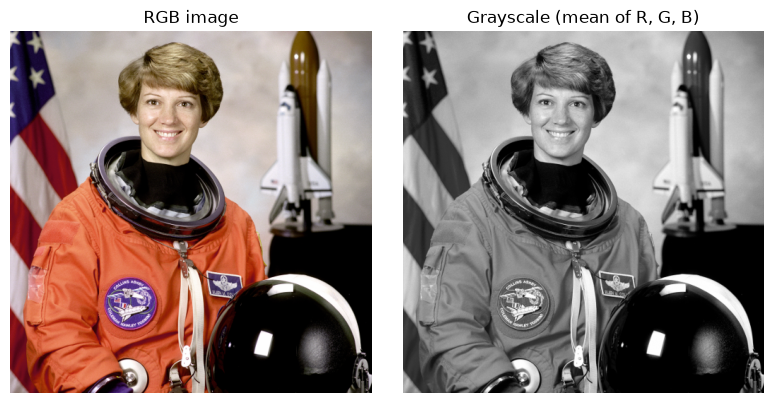

In [4]:
def rgb_to_gray_mean(rgb):
    f = rgb.astype(np.float64)                      # avoid uint8 overflow while adding
    gray = (f[:, :, 0] + f[:, :, 1] + f[:, :, 2]) / 3
    return np.round(gray).astype(np.uint8)

gray_mean = rgb_to_gray_mean(rgb)
show([rgb, gray_mean], ['RGB image', 'Grayscale (mean of R, G, B)'])

## Case 2

> **Case 2:** Input the weightage of the three planes R, G, B from the user. Each weight is between 0 and 1, and the sum of all three weights is equal to 1 (example: weightage of R, G, B is 0.7, 0.2, 0.1 respectively).

Enter weight of R (0-1): no valid input, using default = 0.7
Enter weight of G (0-1): no valid input, using default = 0.2
Enter weight of B (0-1): no valid input, using default = 0.1
Using weights  R = 0.700, G = 0.200, B = 0.100


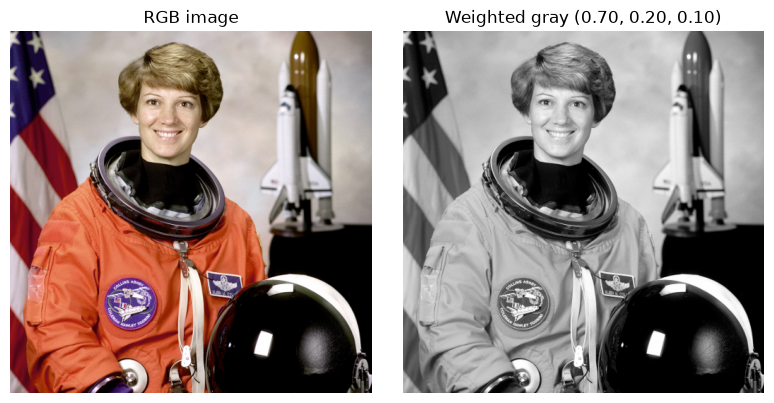

In [5]:
def rgb_to_gray_weighted(rgb, wR, wG, wB):
    f = rgb.astype(np.float64)
    gray = wR * f[:, :, 0] + wG * f[:, :, 1] + wB * f[:, :, 2]
    return np.clip(np.round(gray), 0, 255).astype(np.uint8)

wR = ask("Enter weight of R (0-1)", 0.7)
wG = ask("Enter weight of G (0-1)", 0.2)
wB = ask("Enter weight of B (0-1)", 0.1)

# validation: each weight in [0, 1] and the sum must be 1
if not all(0 <= w <= 1 for w in (wR, wG, wB)):
    print("Each weight must be between 0 and 1 -> using the example weights 0.7, 0.2, 0.1")
    wR, wG, wB = 0.7, 0.2, 0.1
elif not np.isclose(wR + wG + wB, 1.0):
    s = wR + wG + wB
    print(f"Weights add up to {s:.3f}, not 1 -> normalising them")
    wR, wG, wB = wR / s, wG / s, wB / s

print(f"Using weights  R = {wR:.3f}, G = {wG:.3f}, B = {wB:.3f}")
gray_weighted = rgb_to_gray_weighted(rgb, wR, wG, wB)
show([rgb, gray_weighted], ['RGB image', f'Weighted gray ({wR:.2f}, {wG:.2f}, {wB:.2f})'])

### Comparison of different weightings
The standard luminance weights (ITU-R BT.601, used by OpenCV/MATLAB `rgb2gray`) are 0.299, 0.587, 0.114, because the eye is most sensitive to green.

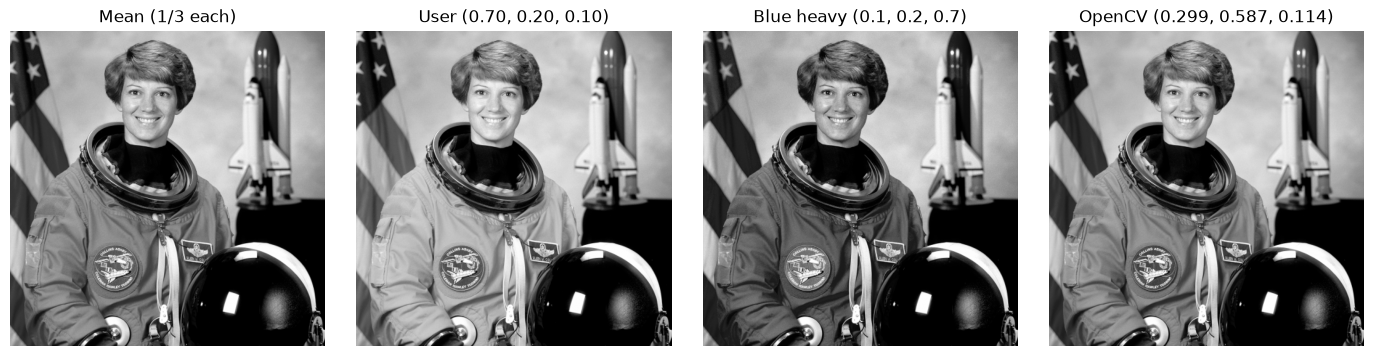

In [6]:
gray_std = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
show([gray_mean, gray_weighted, rgb_to_gray_weighted(rgb, 0.1, 0.2, 0.7), gray_std],
     ['Mean (1/3 each)', f'User ({wR:.2f}, {wG:.2f}, {wB:.2f})', 'Blue heavy (0.1, 0.2, 0.7)',
      'OpenCV (0.299, 0.587, 0.114)'], size=3.5)

**Observation:** The weights decide which colours look bright. With a high R weight the red/skin regions turn bright; with a high B weight the blue regions do. The mean gives every channel equal importance, while the luminance weights give the result that looks most natural to the eye.